# TP1 — Le réseau du métro de Montréal
## Carnet, graphes, Dijkstra — et un premier modèle

**Nom :** _Laura SORRO_ &nbsp;&nbsp;&nbsp; **Coéquipier :** _pas de coéquipier_ &nbsp;&nbsp;&nbsp; **Groupe :** _LauraS_

---

Ce TP se fait **seul ou en équipe de 2**. Une équipe remet **un seul carnet** et
indique à la fin qui a fait quoi.

**Chaque question, y compris les questions de code, se termine par une cellule
d'observation en Markdown.** Écrivez-y ce que vous constatez, en phrases complètes,
en français. Une cellule d'observation laissée telle quelle vaut 0 pour la question.

Avant de remettre : **Kernel → Redémarrer et tout exécuter**.

## Partie 2 — Charger et explorer le réseau

Le fichier `donnees/metro_montreal.csv` contient une ligne par lien entre deux
stations voisines, avec la durée approximative en minutes. Le fichier
`donnees/stations.csv` donne la ligne de chaque station.

In [1]:
import csv

reseau = {}

with open("donnees/metro_montreal.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        a = ligne["station_a"]
        b = ligne["station_b"]
        minutes = int(ligne["minutes"])
        reseau.setdefault(a, []).append((b, minutes))
        reseau.setdefault(b, []).append((a, minutes))

infos_station = {}
with open("donnees/stations.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        infos_station[ligne["station"]] = ligne


def voisins(reseau, station):
    return [nom for nom, minutes in reseau[station]]


def temps(reseau, a, b):
    for nom, minutes in reseau[a]:
        if nom == b:
            return minutes
    return None

**Q2.1** — Affichez le nombre de stations et le nombre de **liens**.

In [2]:
# Q2.1
print(len(reseau), "stations")
nombre_liens = sum(len(liste_voisines) for liste_voisines in reseau.values()) // 2
#  Chaque lien apparaît deux fois dans le dictionnaire (A -> B et B -> A), d'où la division par 2
print(nombre_liens, "liens")

68 stations
69 liens


> **Observation — obligatoire.** Comparez vos deux nombres. Qu'est-ce que leur écart vous dit sur la forme du réseau ?
>
> Le réseau est formé de 68 stations (des sommets) et de 69 liens (des arêtes). La différence entre les deux est de 1
> (le nombre de liens correspond au nombre de stations + 1). Cela nous indique que la forme du réseau n'est pas un arbre,
> car il aurait 67 arêtes (68 sommets - 1). Si ce n'est pas un arbre, il a 2 arêtes en plus. Donc cela implique qu'il contient
> des cycles. Deux stations peuvent être reliées par plusieurs chemins en conséquence : entre Snowdon et Jean-Talon, il existe
> deux chemins (la ligne orange et la ligne bleue). Entre Lionel-Groulx et Berri-UQAM il existe deux autres chemins (la ligne orange
> et la ligne verte).

**Q2.2** — Trouvez la ou les stations qui ont le plus de voisins, puis la liste des
**terminus**.

In [3]:
# Q2.2
max_voisines = max(len(liste_voisines) for liste_voisines in reseau.values())
stations_max_voisines = [station for station, liste_voisines in reseau.items() if len(liste_voisines) == max_voisines]

terminus = [station for station, liste_voisines in reseau.items() if len(liste_voisines) == 1]
print("Station(s) avec le plus de voisins :", stations_max_voisines)
print("Terminus :", terminus)

Station(s) avec le plus de voisins : ['Berri-UQAM']
Terminus : ['Angrignon', 'Honore-Beaugrand', 'Cote-Vertu', 'Montmorency', 'Saint-Michel', 'Longueuil']


> **Observation — obligatoire.** Pourquoi ces stations-là ? Expliquez ce que leur nombre de voisins traduit dans le vrai réseau.
>
> Berri-UQAM est une station de correspondance avec 3 lignes, c'est pour cela qu'elle a le plus de voisins (5) : 2 avec la ligne verte,
> 2 avec la ligne orange et 1 avec la ligne jaune. Par contre, nous ne la voyons pas dans la liste des terminus : la ligne jaune a pour
> terminus Longueuil ET Berri-UQAM. Jean-Talon suit ensuite avec 4 voisins (2 avec la ligne orange et 2 avec la ligne bleue), ainsi que
> Lionel-Groulx (2 avec la ligne orange et 2 avec la ligne verte).
>
> Les 6 terminus trouvés sont des stations sans correspondance : une fois arrivé au bout, le train repart dans l'autre sens. Nous ne
> retenons que les stations qui ont un seul voisin. Mais nous ne considérons pas qu'un terminus peut avoir plus d'un voisin.
> En réalité, il existe 8 terminus de 4 lignes avec 2 terminus chacune. Il manque les stations Berri-UQAM (expliquée précédemment) et
> Snowdon : celle-ci a 3 voisins (2 sur la ligne orange et une sur la ligne bleue) et est le terminus de la ligne bleue avec la station
> Saint-Michel. Le critère du degré 1 n'est donc pas suffisant. Il faudrait rajouter un autre critère de recherche : compter les voisins
> ligne par ligne.


**Q2.3** — Comptez combien de tronçons durent 1, 2 et 3 minutes.

In [4]:
# Q2.3
# Pour rappel, chaque lien apparaît deux fois dans le réseau, vu dans Q2.1
for duree in range(1, 4):
    nombre_troncons = 0
    for station in reseau:
        for voisine, minutes in reseau[station]:
            if minutes == duree:
                nombre_troncons += 1
    print(f"Nombre de tronçons de {duree} minute(s) :", nombre_troncons // 2)

Nombre de tronçons de 1 minute(s) : 13
Nombre de tronçons de 2 minute(s) : 37
Nombre de tronçons de 3 minute(s) : 19


> **Observation — obligatoire.** Quelle durée domine, et dans quelle proportion ? Gardez ce chiffre : il servira à la partie 5.
>
> La durée qui domine est 2 minutes, avec 37 tronçons sur 69 (53,6 %).
> Suivent les tronçons de 3 minutes, avec 19 tronçons pour 27,5 %, puis les tronçons de 1 minute, avec 13 tronçons pour 18,8 %.
> Les tronçons de 3 minutes sont plus fréquents que ceux de 1 minute et peuvent signifier une plus longue distance.
> Ce résultat est cohérent, l'énoncé indique une durée d'environ 2 minutes par inter-station.

## Partie 3 — Le parcours en largeur, et son arbre

**Q3.1** — Complétez `bfs(reseau, depart)`. Il rend `distance` (en nombre d'arrêts)
et `precedent`.

In [5]:
# Q3.1
from collections import deque

def bfs(reseau, depart):
    distance = {depart: 0}
    precedent = {}
    file = deque([depart])
    while file:
        station = file.popleft()
        for suivante in voisins(reseau, station):
            if suivante not in distance:
                distance[suivante] = distance[station] + 1
                precedent[suivante] = station
                file.append(suivante)
    return distance, precedent

distance, precedent = bfs(reseau, "Berri-UQAM")
print("Nombre d'arêtes de l'arbre de parcours depuis Berri-UQAM (paires dans precedent) :", len(precedent))

Nombre d'arêtes de l'arbre de parcours depuis Berri-UQAM (paires dans precedent) : 67


> **Observation — obligatoire.** Décrivez en vos mots ce que contient `precedent` à la fin, et à quoi il servira.
>
> `precedent` contient des clés et des valeurs. Les clés sont les stations visitées, sauf le départ. Chaque valeur est le parent de sa station-clé dans l'arbre. Le départ est absent car il n'a pas de précédent.
>
> Chaque paire est une arête : on en compte 67 pour 68 stations, soit n − 1, ce qui forme un arbre. Les 2 arêtes laissées de côté par le BFS correspondent aux cycles trouvés à la Q2.1.
>
> `precedent` servira à remonter les stations précédentes de l'arrivée jusqu'au départ pour retrouver le trajet. On obtient ainsi le trajet à l'envers, de l'arrivée vers le départ : il faut donc l'inverser à la fin. Il servira aussi à dessiner l'arbre de parcours pour mieux visualiser tous les chemins depuis le départ, c'est-à-dire le parcours entier.

**Q3.2** — Lancez le BFS depuis la station de votre choix. Combien de stations sont
atteintes ? Laquelle est la plus loin, en nombre d'arrêts ?

In [6]:
# Q3.2
distance, precedent = bfs(reseau, "Henri-Bourassa")
print("Nombre de stations atteintes :", len(distance))

max_distance = max(distance.values())
# Toutes les stations à la distance maximale (en cas d'égalité)
stations_max_distance = [station for station, dist in distance.items() if dist == max_distance]
print("Station(s) la plus éloignée :", stations_max_distance)
print("Distance (en arrêts) :", max_distance)

Nombre de stations atteintes : 68
Station(s) la plus éloignée : ['Angrignon']
Distance (en arrêts) : 23


> **Observation — obligatoire.** Le nombre de stations atteintes vous apprend quelque chose sur le réseau : quoi ? Et la station la plus loin vous surprend-elle ?
>
> Les 68 stations atteintes nous apprennent qu'il existe un chemin entre deux stations quelconques. C'est donc un graphe connexe.
>
> La station la plus loin ne me surprend pas : Henri-Bourassa se situe au nord, tandis qu'Angrignon se situe au sud-ouest. Elles sont à des
> extrémités opposées. La distance est cohérente.
> Avec Dijkstra (que nous verrons en partie 4), le trajet le plus rapide en minutes pourrait passer par d'autres stations, et la station la
> plus éloignée pourrait être différente de celle trouvée avec le BFS.

**Q3.3** — Dessinez l'**arbre de parcours** (les 3 premiers niveaux) avec
`graphviz`.

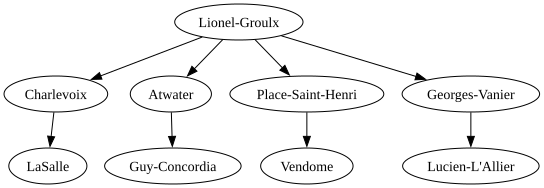

In [7]:
# Q3.3
from graphviz import Digraph

def dessiner_arbre(reseau, depart, niveaux=3):
    distance, precedent = bfs(reseau, depart)
    dot = Digraph(f"Arbre de parcours depuis {depart}")
    dot.node(depart)
    for station, dist in distance.items():
        if dist < niveaux and station != depart:
            dot.node(station)
            dot.edge(precedent[station], station)
    return dot

dot = dessiner_arbre(reseau, "Lionel-Groulx", niveaux=3)
dot

> **Observation — obligatoire.** Le réseau n'est pas un arbre, et pourtant votre dessin en est un. Expliquez pourquoi.
>
> Le dessin montre tous les chemins les plus courts (en arrêts) depuis le départ, limités aux premiers niveaux. Les arêtes viennent de
> `precedent`. Chaque station n'a qu'un seul parent. Cela l'empêche d'être reliée à la racine par deux chemins différents. Or un cycle,
> c'est justement deux chemins entre les mêmes stations.
>
> Quand le BFS rencontre une station déjà vue, les arêtes qui fermeraient un cycle sont laissées de côté. C'est ainsi que nous coupons
> les cycles et que notre dessin devient un arbre.
> Remarque : autour de Lionel-Groulx, dans les premiers niveaux, il n'y a de toute façon aucun cycle. Le dessin serait donc un arbre même
> sans le BFS.

## Partie 4 — Dijkstra, en minutes

**Q4.1** — Complétez `plus_petite_case`, `relacher` et `dijkstra`.

In [8]:
# Q4.1
INFINI = 9999

def plus_petite_case(distance, barres):
    record = INFINI
    choisie = None
    for station in distance:
        if station not in barres and distance[station] < record:
            record = distance[station]
            choisie = station
    return choisie


def relacher(distance, precedent, a, b, minutes):
    if distance[a] + minutes < distance[b]:
        distance[b] = distance[a] + minutes
        precedent[b] = a


def dijkstra(reseau, depart):
    distance = {station: INFINI for station in reseau}
    distance[depart] = 0
    precedent = {}
    barres = set()
    while len(barres) < len(reseau):
        station = plus_petite_case(distance, barres)
        barres.add(station)
        for voisine, minutes in reseau[station]:
            relacher(distance, precedent, station, voisine, minutes)
    return distance, precedent

> **Observation — obligatoire.** À quoi sert l'ensemble `barres` ? Que se passerait-il si on l'oubliait ?
>
> Une station « barrée » est une station dont la distance ne changera pas, elle est définitive. Nous connaissons
> sa distance : c'est la durée du plus court chemin depuis le départ.
>
> Le réseau du TP a des durées de 1, 2 ou 3 minutes. Pour atteindre autrement une station déjà « barrée »,
> il faudrait passer par une station plus éloignée du départ, en ajoutant des minutes positives (les stations 
> non « barrées » ont une distance plus grande ou égale). Une distance « barrée » ne peut plus baisser, un détour
> ne peut que rallonger le chemin. Dijkstra ne fonctionne pas avec des poids négatifs, c'est pour cela qu'il
> fonctionne ici : il n'y a aucun poids négatif.
>
> Sans la ligne `barres.add(station)`, `barres` existerait mais resterait vide. `plus_petite_case` trouverait 
> une station (celle du départ) et ne changerait pas de choix car la distance serait la plus courte : 0. `len(barres)` 
> resterait à 0, et la condition du `while` ne deviendrait jamais fausse. Nous verrions une boucle qui ne s'arrêterait jamais.


**Q4.2** — Complétez `chemin` (la remontée des précédents) et `duree`.

In [9]:
# Q4.2
def chemin(precedent, depart, arrivee):
    route = [arrivee]
    while route[-1] != depart:
        route.append(precedent[route[-1]])
    route.reverse()
    return route


def duree(reseau, route):
    total = 0
    for i in range(len(route) - 1):
        total += temps(reseau, route[i], route[i + 1])
    return total

> **Observation — obligatoire.** `chemin` remonte à l'envers puis retourne la liste. Pourquoi ne peut-on pas la construire à l'endroit directement ?
>
> On ne peut pas la reconstruire à l'endroit directement, car `precedent` indique seulement d'où l'on vient, jamais où l'on va. 
> Chaque station connaît sa station précédente, mais pas la suivante. C'est pour cela que l'on part plutôt de l'arrivée pour 
> retracer son chemin jusqu'au départ, ce qui donne la liste à l'envers. Il suffit ensuite de la retourner pour avoir le chemin 
> à l'endroit.

**Q4.3** — Affichez le trajet le plus rapide entre deux stations de votre choix,
avec sa durée.

In [10]:
# Q4.3
depart = "De l'Eglise"
arrivee = "Henri-Bourassa"
distance, precedent = dijkstra(reseau, depart)
trajet = chemin(precedent, depart, arrivee)
print("Trajet le plus rapide de", depart, "à", arrivee, ":", trajet)
print("Durée totale :", duree(reseau, trajet), "minutes")


Trajet le plus rapide de De l'Eglise à Henri-Bourassa : ["De l'Eglise", 'LaSalle', 'Charlevoix', 'Lionel-Groulx', 'Atwater', 'Guy-Concordia', 'Peel', 'McGill', 'Place-des-Arts', 'Saint-Laurent', 'Berri-UQAM', 'Sherbrooke', 'Mont-Royal', 'Laurier', 'Rosemont', 'Beaubien', 'Jean-Talon', 'Jarry', 'Cremazie', 'Sauve', 'Henri-Bourassa']
Durée totale : 35 minutes


> **Observation — obligatoire.** Ce trajet correspond-il à celui que vous prendriez dans la vraie vie ? Si non, qu'est-ce qui manque à notre modèle ?
>
> La durée totale calculée est cohérente, mais ce n'est pas le trajet que je prends dans la vraie vie, car je préfère prendre la 
> correspondance à Lionel-Groulx plutôt qu'à Berri-UQAM. Le temps de changement est plus rapide, cela me permet d'éviter une plus forte 
> affluence. Dans nos données, un changement de ligne compte pour 0 minute (l'énoncé dit que les correspondances sont gratuites). Il 
> faudrait ajouter un temps pour chaque correspondance. Le modèle ne tient pas compte de ces points.

## Partie 5 — Comparer les deux, et surligner le chemin

**Q5.1** — Écrivez `comparer(depart, arrivee)` qui affiche, pour chaque algorithme,
le nombre d'arrêts **et** la durée. Testez-la sur **trois** paires de stations, dont
**au moins une** où les deux algorithmes ne donnent pas le même trajet.

In [11]:
# Q5.1
def comparer(depart, arrivee):
    distance_bfs, precedent_bfs = bfs(reseau, depart)
    route_bfs = chemin(precedent_bfs, depart, arrivee)

    distance_dij, precedent_dij = dijkstra(reseau, depart)
    route_dij = chemin(precedent_dij, depart, arrivee)

    # Le nombre d'arrêts est le nombre de tronçons : une station de moins que la route
    print(f"{depart} -> {arrivee}")
    print(f"  BFS      : {len(route_bfs) - 1} arrêts, {duree(reseau, route_bfs)} minutes")
    print(f"  Dijkstra : {len(route_dij) - 1} arrêts, {duree(reseau, route_dij)} minutes")
    print("  Même trajet :", route_bfs == route_dij)
    print()


# Recherche de toutes les paires où le BFS et Dijkstra ne donnent pas le même trajet
paires_divergentes = []
for a in sorted(reseau):
    # Un seul BFS et un seul Dijkstra par station de départ
    distance_bfs, precedent_bfs = bfs(reseau, a)
    distance_dij, precedent_dij = dijkstra(reseau, a)
    for b in sorted(reseau):
        # a < b compare les noms par ordre alphabétique : chaque paire n'est testée qu'une fois
        if a < b and chemin(precedent_bfs, a, b) != chemin(precedent_dij, a, b):
            paires_divergentes.append((a, b))

print(len(paires_divergentes), "paires divergentes")
print(paires_divergentes[:10])
print()

comparer("Henri-Bourassa", "Angrignon")
comparer("De l'Eglise", "Henri-Bourassa")
comparer(paires_divergentes[0][0], paires_divergentes[0][1])

191 paires divergentes
[('Acadie', 'Atwater'), ('Acadie', 'Bonaventure'), ('Acadie', 'Guy-Concordia'), ('Acadie', "Lucien-L'Allier"), ('Acadie', 'Peel'), ('Angrignon', 'Cartier'), ('Angrignon', 'Cremazie'), ('Angrignon', "D'Iberville"), ('Angrignon', 'De Castelnau'), ('Angrignon', 'De la Concorde')]

Henri-Bourassa -> Angrignon
  BFS      : 23 arrêts, 54 minutes
  Dijkstra : 24 arrêts, 44 minutes
  Même trajet : False

De l'Eglise -> Henri-Bourassa
  BFS      : 19 arrêts, 45 minutes
  Dijkstra : 20 arrêts, 35 minutes
  Même trajet : False

Acadie -> Atwater
  BFS      : 10 arrêts, 25 minutes
  Dijkstra : 15 arrêts, 23 minutes
  Même trajet : False



> **Observation — obligatoire.** Sur vos trois paires, à quelle fréquence les deux sont-ils d'accord ? Reliez votre réponse au décompte des durées de la question 2.3.
>
> Sur nos 3 paires, BFS et Dijkstra ne tombent jamais d'accord : BFS vise le moins d'arrêts, alors que Dijkstra privilégie la vitesse. Par 
> exemple d'Henri-Bourassa à Angrignon : 23 arrêts en 54 min versus 24 arrêts en 44 min.
>
> C'est pourtant une exception. Sur l'ensemble du réseau (2 278 paires), ils concordent à 91,6 % (68 stations x 67 arêtes / 2 = 2 278 paires.
> (2 278 paires - 191 paires divergentes) / 2 278 paires = 91,6 %). Comme la majorité des tronçons durent 2 min (53,6 %), le nombre d'arrêts
> reflète presque toujours la durée. Les différences apparaissent sur les longs trajets traversant les cycles du réseau. Sur les 191 paires
> divergentes, la plus courte compte 7 arrêts (BFS). C'est là que le poids des tronçons de 1 min (18,8 %) et de 3 min (27,5 %) bascule la
> balance : un parcours avec plus d'arrêts mais des tronçons plus courts finit par être plus rapide.


**Q5.2** — Sur votre paire divergente, **surlignez le chemin de Dijkstra** dans le
dessin : les arêtes du chemin en **rouge et en épais**, la durée de chaque tronçon en
étiquette, et les stations du chemin remplies d'une couleur.

> **Les attributs à utiliser.** Sur une arête : `color="red"`, `penwidth="3"`,
> `fontcolor="red"`. Sur un sommet : `style="filled"`, `fillcolor="#ffd9d9"`.
> Le reste — quelles arêtes dessiner, comment reconnaître celles du chemin — est à
> vous.

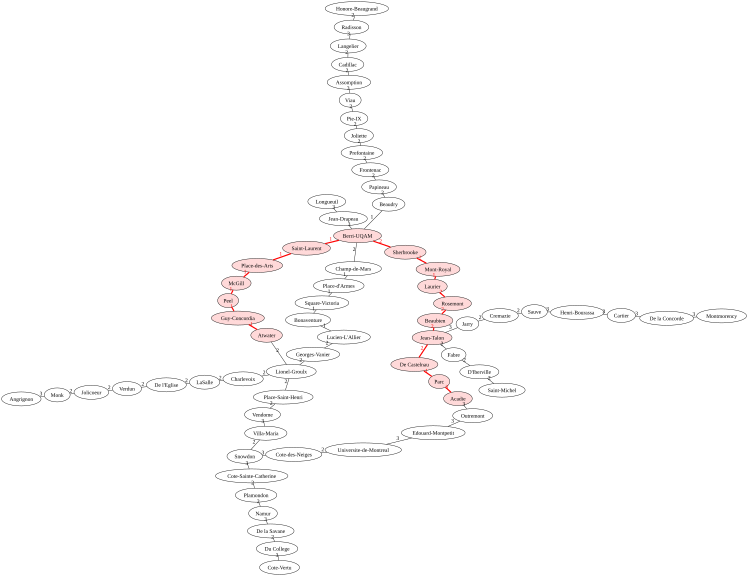

In [12]:
# Q5.2
from graphviz import Graph

def dessiner_chemin(reseau, depart, arrivee):
    distance, precedent = dijkstra(reseau, depart)
    route = chemin(precedent, depart, arrivee)

    # Les tronçons du chemin, sous forme de paires (station, station suivante)
    aretes_chemin = []
    for i in range(len(route) - 1):
        aretes_chemin.append((route[i], route[i + 1]))

    # Graph et non Digraph : les tronçons se parcourent dans les deux sens
    dot = Graph(f"Chemin de Dijkstra de {depart} à {arrivee}")

    # Les stations du chemin sont remplies de couleur
    for station in reseau:
        if station in route:
            dot.node(station, style="filled", fillcolor="#ffd9d9")
        else:
            dot.node(station)

    for a in reseau:
        for b, minutes in reseau[a]:
            # Chaque lien est rangé deux fois dans reseau (Q2.1) : a < b n'en garde qu'un
            if a < b:
                # Un tronçon du chemin peut être rangé dans un sens ou dans l'autre
                if (a, b) in aretes_chemin or (b, a) in aretes_chemin:
                    dot.edge(a, b, label=str(minutes), color="red", penwidth="3", fontcolor="red")
                else:
                    dot.edge(a, b, label=str(minutes))
    return dot

dot = dessiner_chemin(reseau, "Acadie", "Atwater")
# Le moteur neato place les stations comme sur une carte, au lieu de les ranger en niveaux
# (source : graphviz.readthedocs.io, propriété engine)
dot.engine = "neato"
# overlap="false" : les stations ne se chevauchent pas ; size : taille maximale du dessin,
# en pouces (source : graphviz.org/doc/info/attrs.html)
dot.attr(overlap="false", size="12,8")
dot

> **Observation — obligatoire.** Décrivez ce que votre dessin rend visible et que la liste de stations ne montrait pas.
>
> Le dessin montre le trajet dans l'ensemble du réseau, ce que la liste de stations ne permettait pas. On y voit que le réseau 
> forme une grande boucle entre Acadie et Atwater. Dijkstra en prend un côté, par Jean-Talon et Berri-UQAM. Le BFS aurait pris 
> l'autre côté, plus court en arrêts, par Snowdon et Lionel-Groulx.
>
> Les étiquettes rendent ce choix compréhensible : la route par Snowdon compte moins d'arrêts, mais plusieurs de ses tronçons 
> sur la ligne bleue durent 3 minutes. La route de Dijkstra compte 5 arrêts de plus, mais elle finit par 6 tronçons de 1 minute 
> sur la ligne verte, entre Berri-UQAM et Atwater. Elle gagne ainsi 2 minutes (23 contre 25). On voit aussi les deux changements 
> de ligne, à Jean-Talon et à Berri-UQAM, qui ne coûtent rien dans notre modèle (Q4.3). Une liste de 16 stations ne montre ni la 
> forme du détour, ni la durée de chaque tronçon, ni l'autre route possible.

---
## Partie 6 — Construire un tableau de données

Un modèle a besoin d'un **tableau** : une ligne par exemple, une colonne par
**donnée**, et une colonne à part pour l'**étiquette**.

Ici, **un exemple = une station**, et l'étiquette est sa **ligne**. Les données,
vous les fabriquez avec **votre propre travail des parties 3 et 4**.

On laisse de côté les stations de la ligne jaune : il y en a trop peu.

**Q6.1** — Pour chaque station retenue, fabriquez la liste de ses mesures :

1. son nombre de voisins ;
2. la durée moyenne de ses tronçons ;
3. la durée de son plus long tronçon ;
4. le nombre d'**arrêts** qui la séparent d'un **repère** *(votre BFS)* ;
5. le nombre de **minutes** qui l'en séparent *(votre Dijkstra)*.

Écrivez `mesures(station, nb_reperes)` de façon à pouvoir ajouter des repères
ensuite, et construisez `X_1repere` ainsi que `y`.

In [13]:
REPERES = ["Berri-UQAM", "Snowdon", "Honore-Beaugrand"]

stations_retenues = [s for s in sorted(reseau) if infos_station[s]["ligne"] != "jaune"]
y = [infos_station[s]["ligne"] for s in stations_retenues]
print(len(stations_retenues), "stations retenues")

# Q6.1

distances_bfs = {}
distances_dij = {}
for repere in REPERES:
    distance, precedent = bfs(reseau, repere)
    distances_bfs[repere] = distance
    distance, precedent = dijkstra(reseau, repere)
    distances_dij[repere] = distance


def mesures(station, nb_reperes):
    durees = []
    for voisine, minutes in reseau[station]:
        durees.append(minutes)

    liste = [len(durees), sum(durees) / len(durees), max(durees)]

    for repere in REPERES[:nb_reperes]:
        liste.append(distances_bfs[repere][station])
        liste.append(distances_dij[repere][station])
    return liste


X_1repere = [mesures(s, 1) for s in stations_retenues]
print(len(X_1repere), "exemples")
print(stations_retenues[0], X_1repere[0])

66 stations retenues
66 exemples
Acadie [2, 3.0, 3, 9, 17]


> **Observation — obligatoire.** Lesquelles de vos cinq mesures viennent des fichiers fournis, et lesquelles viennent de votre propre code ? Qui a choisi les repères ?
>
> Pour les trois premières mesures (le nombre de voisins, la durée moyenne et la durée du plus long tronçon), les calculs sont tirés 
> directement du fichier `metro_montreal.csv`. Il suffit de compter les tronçons reliés à chaque station, puis de calculer la moyenne 
> et le maximum de leurs durées.
>
> Les mesures 4 et 5, soit le nombre d'arrêts et la durée en minutes pour atteindre une station repère, viennent de mon propre code : 
> elles ne se trouvent dans aucun fichier et sont calculées sur mesure par mes algorithmes BFS et Dijkstra. L'étiquette de ligne 
> associée à chaque station provient du fichier `stations.csv`.
>
> Enfin, le choix des repères : la liste `REPERES` ("Berri-UQAM", "Snowdon" et "Honore-Beaugrand") est directement imposée dans le 
> squelette de départ. Cette contrainte a une incidence directe sur les résultats, puisque les mesures 4 et 5 dépendent entièrement 
> de la station choisie comme point de référence.

**Q6.2** — Comptez combien de stations portent chaque étiquette, et déduisez-en la
note qu'obtiendrait un modèle qui répondrait **toujours la même chose**.

In [14]:
# Q6.2
compte = {}
for ligne in y:
    if ligne in compte:
        compte[ligne] = compte[ligne] + 1
    else:
        compte[ligne] = 1

for ligne in compte:
    print(f"{ligne} : {compte[ligne]} stations")

ligne_max = None
nb_max = 0
for ligne in compte:
    if compte[ligne] > nb_max:
        nb_max = compte[ligne]
        ligne_max = ligne

note = nb_max / len(y) * 100
print(f"Un modèle qui répond toujours « {ligne_max} » aurait raison {nb_max} fois sur {len(y)}, soit {note:.1f} %")

bleue : 10 stations
verte : 27 stations
orange : 29 stations
Un modèle qui répond toujours « orange » aurait raison 29 fois sur 66, soit 43.9 %


> **Observation — obligatoire.** Notez ce pourcentage. C'est la barre que votre modèle devra dépasser pour servir à quelque chose.
>
> La ligne orange est la plus représentée, comptant à elle seule 29 stations sur 66. Un modèle très basique qui prédirait 
> systématiquement « orange », sans même analyser les données, obtiendrait ainsi un taux de réussite de 43,9 %. C'est le seuil 
> de base à dépasser : tout modèle qui fait moins bien qu'un choix constant à 43,9 % n'apporte absolument rien.
>
> On constate également que les classes sont nettement déséquilibrées : si l'orange et la verte regroupent respectivement 29 et 27 stations,
> la ligne bleue n'en compte que 10 (soit 15,2 %). Résultat : se fier uniquement à la note globale peut être trompeur. Un modèle 
> pourrait très bien afficher une excellente note en prédisant correctement l'orange et la verte, tout en manquant systématiquement 
> la bleue.

## Partie 7 — Entraîner un modèle, et le noter honnêtement

**Q7.1** — Coupez en deux paquets (70 / 30), entraînez un `DecisionTreeClassifier`,
et affichez **deux** notes : sur les stations apprises, et sur les stations jamais
vues.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Q7.1
X_train, X_test, y_train, y_test = train_test_split(X_1repere, y, test_size=0.3, random_state=0)

modele = DecisionTreeClassifier(random_state=0)
modele.fit(X_train, y_train)

note_apprises = modele.score(X_train, y_train) * 100
note_jamais_vues = modele.score(X_test, y_test) * 100
print(f"Stations apprises    : {note_apprises:.1f} %")
print(f"Stations jamais vues : {note_jamais_vues:.1f} %")

Stations apprises    : 95.7 %
Stations jamais vues : 35.0 %


> **Observation — obligatoire.** Vos deux notes sont très différentes. Comment s'appelle ce phénomène, et laquelle des deux est honnête ?
>
> L'écart est frappant : le modèle atteint 95,7 % sur les données d'entraînement, mais chute à seulement 35,0 % sur les stations inédites. 
> C'est du surapprentissage presque total : sans limite de profondeur, l'arbre de décision a quasiment appris par cœur les stations 
> d'entraînement au lieu de dégager une vraie règle générale (il ne se trompe que sur 2 stations qu'il avait pourtant vues). La 
> seule note qui compte vraiment est celle sur les stations jamais vues, puisqu'elle mesure la capacité réelle du modèle à généraliser sur 
> de nouvelles données (ce qui est le but recherché). Évaluer le modèle sur son jeu d'entraînement revient à donner un examen à un élève en 
> lui fournissant les réponses à l'avance.
>
> En s'appuyant sur un seul repère, le modèle tombe sous le seuil de 43,9 % établi à la Q6.2 : il fait donc pire qu'un prédicteur naïf qui 
> répondrait toujours « orange ». Sur cette coupe de données, cela suggère fortement que ces 5 mesures ne suffisent pas à identifier de 
> façon fiable la ligne d'une station.

**Q7.2** — Refaites la même chose avec **2** puis **3** repères. Affichez les trois
notes côte à côte.

In [16]:
# Q7.2
X_2reperes = [mesures(s, 2) for s in stations_retenues]
X_3reperes = [mesures(s, 3) for s in stations_retenues]

for nb, X in [(1, X_1repere), (2, X_2reperes), (3, X_3reperes)]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
    modele = DecisionTreeClassifier(random_state=0)
    modele.fit(X_train, y_train)
    note = modele.score(X_test, y_test) * 100
    print(f"{nb} repère(s) : {note:.1f} %")

# Q7.2 - recherche des stations aux mesures identiques
for nb, X in [(1, X_1repere), (3, X_3reperes)]:
    print(f"Avec {nb} repère(s) :")
    for i in range(len(stations_retenues)):
        for j in range(i + 1, len(stations_retenues)):
            if X[i] == X[j] and y[i] != y[j]:
                print(" ", stations_retenues[i], y[i], "et", stations_retenues[j], y[j], ":", X[i])

# Q7.2 - mesures de Beaubien et Joliette avec 3 repères (citées dans l'observation)
print("Beaubien et Joliette avec 3 repères :")
for station in ["Beaubien", "Joliette"]:
    i = stations_retenues.index(station)
    print(" ", station, y[i], ":", X_3reperes[i])

1 repère(s) : 35.0 %
2 repère(s) : 65.0 %
3 repère(s) : 70.0 %
Avec 1 repère(s) :
  Beaubien orange et Joliette verte : [2, 2.0, 2, 5, 9]
  Charlevoix verte et Place-Saint-Henri orange : [2, 2.0, 2, 8, 10]
  Cote-Sainte-Catherine orange et Cote-des-Neiges bleue : [2, 2.5, 3, 12, 20]
  Prefontaine verte et Rosemont orange : [2, 2.0, 2, 4, 7]
Avec 3 repère(s) :
  Cote-Sainte-Catherine orange et Cote-des-Neiges bleue : [2, 2.5, 3, 12, 20, 1, 3, 24, 45]
Beaubien et Joliette avec 3 repères :
  Beaubien orange : [2, 2.0, 2, 5, 9, 9, 22, 17, 34]
  Joliette verte : [2, 2.0, 2, 5, 9, 16, 26, 7, 16]


> **Observation — obligatoire.** Qu'est-ce qui change, et pourquoi un seul repère ne suffisait-il pas ? Pensez à deux stations situées de part et d'autre du repère.
>
> Plus on ajoute de repères, plus la note grimpe sur les stations jamais vues : 35,0 % avec un repère, 65,0 % avec deux et 70,0 % avec trois. Avec un seul repère, le modèle faisait pire que la barre de 43,9 % de la Q6.2. Dès deux repères, il la dépasse nettement.
> 
> Un seul repère ne suffisait pas parce qu'une distance indique à quel point une station est loin du repère, mais pas dans quelle direction. > Par exemple, Beaubien (orange), au nord de Berri-UQAM, et Joliette (verte), à l'est, sont toutes deux à 5 arrêts et 9 minutes de 
> Berri-UQAM. Elles ont aussi 2 voisins et des tronçons de 2 minutes. Leurs cinq mesures sont donc identiques ([2, 2.0, 2, 5, 9]) alors que > leurs lignes diffèrent, et le modèle ne peut pas les distinguer. J'ai trouvé quatre paires de ce genre : Beaubien et Joliette, Charlevoix > et Place-Saint-Henri, Cote-Sainte-Catherine et Cote-des-Neiges, Prefontaine et Rosemont. Deux de ces paires, Prefontaine et Rosemont ainsi
> que Cote-Sainte-Catherine et Cote-des-Neiges, se trouvaient entièrement dans le paquet d'entraînement. Elles expliquent les 2 erreurs de 
> l'arbre sur les stations apprises à la Q7.1 : même en mémorisant tout, il ne peut pas séparer deux exemples identiques qui portent des 
> étiquettes différentes.
>
> Les autres repères lèvent la plupart de ces confusions. Beaubien et Joliette se distinguent avec Snowdon (9 contre 16 arrêts) et avec 
> Honore-Beaugrand (17 contre 7). Croiser les distances à plusieurs repères distingue donc la plupart des stations, mais pas toutes. 
> Cote-Sainte-Catherine et Cote-des-Neiges restent identiques même avec trois repères ([2, 2.5, 3, 12, 20, 1, 3, 24, 45]) : elles sont 
> situées de chaque côté de Snowdon, chacune à 1 arrêt et 3 minutes, et leurs chemins vers Berri-UQAM et Honore-Beaugrand passent par 
> Snowdon. C'est la limite de cette méthode : un repère ne sépare pas deux stations placées symétriquement autour de lui. Le gain du 
> troisième repère reste néanmoins limité (+5 points, soit une station de plus bien classée sur 20).

**Q7.3** — Sur vos meilleures mesures, comparez un **arbre seul** à une **forêt
aléatoire**. Relancez chacun avec `random_state` valant 0, 1, 2, 3 puis 4, et
affichez pour chaque modèle ses cinq notes, leur **moyenne** et l'**écart** entre la
plus haute et la plus basse.

In [17]:
# Q7.3
for nom in ["Arbre seul", "Forêt aléatoire"]:
    notes = []
    for rs in range(5):
        X_train, X_test, y_train, y_test = train_test_split(X_3reperes, y, test_size=0.3, random_state=rs)
        if nom == "Arbre seul":
            modele = DecisionTreeClassifier(random_state=rs)
        else:
            modele = RandomForestClassifier(random_state=rs)
        modele.fit(X_train, y_train)
        notes.append(round(modele.score(X_test, y_test) * 100, 1))

    moyenne = sum(notes) / len(notes)
    ecart = max(notes) - min(notes)
    print(f"{nom} : notes {notes}, moyenne {moyenne:.1f} %, écart {ecart:.1f} points")

Arbre seul : notes [70.0, 65.0, 80.0, 60.0, 60.0], moyenne 67.0 %, écart 20.0 points
Forêt aléatoire : notes [65.0, 65.0, 60.0, 60.0, 65.0], moyenne 63.0 %, écart 5.0 points


> **Observation — obligatoire.** La forêt vous a-t-elle aidés ? Appuyez-vous sur la moyenne ET sur l'écart, puis proposez une explication liée au nombre d'exemples dont vous disposez.
>
> Sur les 5 relances, l'arbre seul affiche une moyenne de 67,0 % mais varie considérablement, avec un écart de 20,0 points (entre 60 % 
> et 80 %). De son côté, la forêt aléatoire obtient une moyenne de 63,0 % et resserre son écart à seulement 5,0 points (de 60 % à 65 %). 
> La forêt ne permet donc pas d'améliorer la note globale : sa moyenne recule même de 4 points, ce qui représente l'erreur de moins d'une 
> station en moyenne (chaque station valant 5 points). En contrepartie, elle gagne considérablement en stabilité, avec un écart quatre fois
> plus petit que celui de l'arbre unique.
>
> La taille réduite de l'échantillon explique cette dynamique. Sur 66 stations au total, le jeu de test n'en contient que 20 : la note de 
> l'arbre isolé dépend donc énormément du tirage au sort des données, passant de 80 % sur un découpage à 60 % sur un autre. En regroupant 
> les prédictions de plusieurs arbres, la forêt amortit ces écarts. Mais tous ses arbres apprennent à partir des mêmes 46 stations 
> d'entraînement : leur vote ne peut pas inventer l'information qui manque, et certaines stations restent indiscernables, comme 
> Cote-Sainte-Catherine et Cote-des-Neiges. Avec un volume d'exemples aussi limité, la forêt gagne en régularité, mais pas en note. 
> Dans les deux configurations, les modèles restent bien au-dessus du seuil de 43,9 % établi à la Q6.2.

---
## Partie 8 — Vos conclusions

Répondez en Markdown, **en phrases complètes, en français**. Comptez deux ou trois
phrases par question, et **citez vos propres chiffres**.

**Sur le réseau**

1. Le réseau est-il un **arbre** ? Justifiez avec le nombre de stations et de liens.
2. Quelle station est la mieux connectée, et **pourquoi** celle-là ?
3. Sur vos trois paires, le BFS et Dijkstra donnent-ils souvent la même réponse ?
   Reliez votre réponse au décompte des durées.
4. Décrivez **une** paire où ils diffèrent, et expliquez ce que chacun a optimisé.

**Sur le modèle**

5. Avec un seul repère, quelle note obtenez-vous, et comment se compare-t-elle au
   modèle qui répond toujours la même chose ? Qu'est-ce que ça vous apprend ?
6. Qu'est-ce qui change avec 2 puis 3 repères, et **pourquoi** ?
7. Pourquoi la note sur les stations jamais vues est-elle la seule honnête ?
8. La forêt aléatoire vous a-t-elle aidés ? Appuyez-vous sur les cinq notes et sur
   l'écart.

**Sur l'ensemble**

9. Vos données de la partie 6 viennent de vos propres fonctions. Quel risque cela
   pose-t-il si votre BFS ou votre Dijkstra contient une erreur ?
10. Nommez **une** limite de nos données par rapport au vrai métro, et **une**
    mesure supplémentaire que vous auriez aimé avoir pour le modèle.

### Vos réponses

*(remplacez ce texte)*

1.

2.

3.

4.

5.

6.

7.

8.

9.

10.

---
## Déclaration d'utilisation de l'intelligence artificielle

**Obligatoire, même si vous n'en avez pas utilisé.** Une déclaration absente ou
fausse vaut **0 pour l'ensemble du TP**.

L'IA est permise **pour apprendre**, pas pour produire votre travail. Relisez les
règles de l'énoncé avant de remplir cette section.

**Avez-vous utilisé un outil d'IA ?** Oui

**Si oui, remplissez le tableau :**

| Outil | Pour quelle question | Ce que vous lui avez demandé | Lien de partage de la conversation |
|---|---|---|---|
| Claude (Anthropic) | Q2.3 | Comment traduire une compréhension à deux for en boucles imbriquées, et où remettre un compteur à zéro | https://claude.ai/share/ca2142f9-0717-4107-9dc5-8b2a603fa10e |
| Claude (Anthropic) | Q4.1 | À quoi sert l'ensemble des sommets barrés dans Dijkstra, et ce qui se passerait si on l'oubliait, sur un graphe inventé de 4 sommets | https://claude.ai/share/3619da4b-e658-4120-aafb-dca77c7cb128 |
| Claude (Anthropic) | Q4.1 | L'opération "relâcher une arête" et pourquoi on ne change rien en cas d'égalité, avec un tableau étape par étape sur un petit graphe inventé | https://claude.ai/share/16c148e3-64d2-40fc-844c-1d9d95ab4f4d |
| Claude (Anthropic) | Q5.2 | Après avoir écrit le code : comment colorer et épaissir certaines arêtes seulement, éviter de dessiner deux fois une arête d'un graphe non orienté, et à quoi servent les moteurs dot et neato et les attributs overlap, size et len, sur un exemple inventé | https://claude.ai/share/f4fefe1f-3fb5-45c6-af76-7a0015b95a90 |
| Claude (Anthropic) | Q6.1 | Ce qu'est une mesure et une étiquette dans un tableau de données, et pourquoi une distance jusqu'à un point de repère aide un modèle, sur un exemple inventé | https://claude.ai/share/5cb19857-b3b2-471e-be05-7876c7a20351 |
| Claude (Anthropic) | Q6.2 | Ce qu'est la note d'un modèle qui répond toujours la même chose, et pourquoi elle sert de barre à dépasser, avec des étiquettes inventées | https://claude.ai/share/eb6f1da0-2bd4-4d70-9474-f2e755f1c91f |
| Claude (Anthropic) | Q7.1 | Pourquoi un arbre de décision obtient souvent une note bien plus haute sur les données d'entraînement que sur les données de test, et comment s'appelle ce phénomène, sur un exemple inventé | https://claude.ai/share/b68785e8-f808-4a10-8e93-7b5c90e06795 |
| Claude (Anthropic) | Q7.3 | Pourquoi relancer un modèle avec plusieurs random_state, ce que mesurent la moyenne et l'écart des notes, et si une forêt aléatoire aide quand on a peu d'exemples | https://claude.ai/share/f1014f82-92c9-4a59-aa7d-1cb9157c52ff |
|  |  |  |  |
|  |  |  |  |

**Confirmez, en écrivant « oui » :**

- Je n'ai **pas** collé l'énoncé du TP, en tout ou en partie, dans une conversation
  avec une IA. → Oui
- Je n'ai **pas** collé le contenu des fichiers de données. → Oui
- Je comprends chaque ligne de code que je remets et je peux l'expliquer à l'oral.
  → Oui

---
**Qui a fait quoi :** *(obligatoire si vous êtes deux)*

---
## Avant de remettre

**Vingt points du TP ne portent pas sur vos réponses** : dix sur la tenue de ce
carnet, dix sur votre usage de Git. Relisez les sections 3 et 4 de l'énoncé avant de
déposer votre travail.

**Le carnet.** Faites **Kernel → Redémarrer et tout exécuter** en dernier, et
vérifiez qu'aucune cellule ne produit d'erreur. Puis relisez-le comme si vous ne
l'aviez pas écrit : est-ce qu'on s'y retrouve ? Est-ce que chaque nombre affiché
s'explique sans aller lire le code ? Reste-t-il des cellules d'essai, des variables
au nom obscur, des observations expédiées ? Le français est-il relu ?

**Le dépôt.** Le nom de votre branche et vos messages de commit suivent la
convention vue en cours. Votre historique doit montrer un travail construit au fil du
temps — et, si vous êtes deux, la contribution des deux.

**L'identification.** Nom, coéquipier et groupe en première cellule, « qui a fait
quoi » à la fin, déclaration d'IA remplie même si la réponse est « non », et le
dossier `donnees/` à côté du carnet.

---

*Ensuite : `Publish branch`, `Create Pull Request`, fusion dans `main`, et le lien du
dépôt sur Omnivox.*